# Entrega final, parte 1: pronóstico mensual de órdenes entrantes

**BCD5105 · Modelado matemático · III Cuatrimestre 2026 · Lead University**

**Proyecto:** Pronóstico de las órdenes entrantes de LightForce Orthodontics a escala mensual y diaria

**Grupo:** 2

**Integrantes:** Daniel Vasquez Gonzalez, Santiago Villareal Arley, Maria José Gonzalez Quesada, Sharis Duarte Alvarado

Este notebook reproduce la parte 1 del proyecto: el pronóstico de las órdenes entrantes de cada mes a tres meses vista. Se comparan modelos clásicos (ingenuo, ingenuo estacional, ETS, SARIMA), los mismos con ajuste por días hábiles, una regresión Ridge, Prophet y dos modelos de fundación (Chronos-2 y TimesFM 2.5), todos con la misma validación de ventana expansiva. Respecto del avance se agregan dos cosas: una **variable de intervención del acero** (SARIMAX y Ridge con la proporción de acero, y Chronos-2 con ella como covariable), con dos formas de construirla en el horizonte, y la **cobertura de los intervalos del 80 % y 95 %** en la validación. La parte 2 (pronóstico diario a 15 días) está en `Notebook_2_Pronostico_Diario.ipynb`.

Se ejecuta de principio a fin en un entorno limpio de Colab (Python 3). Los datos se leen de `datos/ordenes_diarias.csv` si el archivo está junto al notebook, o del repositorio público en GitHub si no.

Contenido:
1. Configuración, versiones y semilla
2. Datos y su origen
3. Análisis exploratorio
4. Modelos y validación de ventana expansiva
5. Resultados de la validación
6. Variable de intervención del acero
7. Cobertura de los intervalos
8. Diagnóstico del SARIMA y pronóstico de noviembre de 2026 a enero de 2027
9. Conclusiones

## 1. Configuración, versiones y semilla

In [1]:
%pip install -q statsforecast==2.1.1 prophet==1.5.0 chronos-forecasting==2.3.2 "timesfm[torch]==3.0.2"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, random, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import statsmodels, statsforecast, scipy, sklearn, prophet, torch, timesfm, chronos
from importlib.metadata import version
from scipy.stats import wilcoxon
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, AutoETS, AutoARIMA
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from prophet import Prophet
from chronos import Chronos2Pipeline

warnings.filterwarnings("ignore")
for nombre in ["cmdstanpy", "prophet"]:
    logging.getLogger(nombre).setLevel(logging.ERROR)
SEMILLA = 2026
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)
print("statsmodels", statsmodels.__version__, "| statsforecast", statsforecast.__version__, "| prophet", prophet.__version__)
print("torch", torch.__version__, "| chronos-forecasting", version("chronos-forecasting"), "| timesfm", version("timesfm"))

# Estilo de las figuras: paleta categórica validada (azul, naranja, aqua), rejilla tenue, sin bordes superior/derecho
C = dict(azul="#2a78d6", naranja="#eb6834", aqua="#1baf7a", tinta="#0b0b0b", tinta2="#52514e",
         tenue="#898781", rejilla="#e1e0d9", base="#c3c2b7", fondo="#fcfcfb",
         azul_claro="#86b6ef", azul_medio="#3987e5", azul_oscuro="#1c5cab")
plt.rcParams.update({
    "figure.facecolor": C["fondo"], "axes.facecolor": C["fondo"], "axes.edgecolor": C["base"],
    "axes.labelcolor": C["tinta2"], "xtick.color": C["tenue"], "ytick.color": C["tenue"],
    "text.color": C["tinta"], "axes.grid": True, "grid.color": C["rejilla"], "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "savefig.dpi": 200,
    "savefig.bbox": "tight", "figure.dpi": 110, "legend.frameon": False})
os.makedirs("figuras", exist_ok=True)

nombres_mes = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
FMT_MES = FuncFormatter(lambda x, pos: "%s-%s" % (nombres_mes[mdates.num2date(x).month - 1], mdates.num2date(x).strftime("%y")))   # ej. ene-26

pandas 2.2.3 | numpy 2.4.6 | scipy 1.17.1 | scikit-learn 1.8.0
statsmodels 0.14.6 | statsforecast 2.1.1 | prophet 1.5.0
torch 2.12.1+cpu | chronos-forecasting 2.3.2 | timesfm 3.0.2


## 2. Datos y su origen

**Fuente:** base de datos analítica de LightForce Orthodontics (Databricks), tabla `analytics.manufacturing.mfg_all_orders`, consultada el 12 de noviembre de 2026 con autorización de la empresa. Cada fila de la tabla es un caso de manufactura. Como la base no es pública, el resultado de la consulta (conteos por día, sin datos de casos individuales) se guarda en `datos/ordenes_diarias.csv` dentro del repositorio.

**Definición de orden entrante:** caso nuevo (`order_type = 'New case'`) con fecha de recepción del escaneo (`scan_received_date`). Los _reorders_ reutilizan el escaneo original y quedan fuera. Se cuentan todos los estados, incluso casos luego cancelados, porque la demanda llegó de todos modos.

**Zona horaria:** `scan_received_date` está en UTC. Se pasa a hora de Costa Rica (UTC−6, sin horario de verano) antes de asignar el día, porque el equipo que atiende los casos y el pronóstico diario de la parte 2 están en Costa Rica. A escala mensual el cambio es pequeño (en promedio 17 órdenes por mes respecto de UTC), pero a escala diaria importa: el día laboral de Australia y Nueva Zelanda cae casi completo en el día anterior en Costa Rica (notebook 2).

**Columnas del archivo:** `fecha` (día en hora de Costa Rica), `ordenes` (total), `acero` (bracket de acero inoxidable, producto lanzado en 2026) y `us`, `ca`, `au`, `nz` (órdenes por país de la cuenta; Puerto Rico se suma a EE. UU. y hay una orden de Brasil que solo cuenta en el total). En el notebook se derivan, por mes, `otros` (órdenes que no son de acero, principalmente del bracket cerámico translúcido), `prop_acero` (proporción de acero, la variable de intervención de la sección 6) y `dias_habiles` (lunes a viernes).

Consulta usada:

```sql
-- Órdenes nuevas por día en hora de Costa Rica (UTC-6), por país de la cuenta.
-- Fuente: analytics.manufacturing.mfg_all_orders (Databricks, LightForce).
-- scan_received_date está en UTC; se convierte a America/Costa_Rica antes de tomar la fecha.
-- Puerto Rico (PR) se suma a EE. UU.; acero = brackets de acero inoxidable.
-- Salida: ordenes_diarias.csv (fecha, ordenes, acero, us, ca, au, nz), del 2023-01-01 al 2026-11-11.
WITH o AS (
  SELECT to_date(from_utc_timestamp(scan_received_date, 'America/Costa_Rica')) AS fecha,
         CASE WHEN account_country IN ('US', 'PR') THEN 'US' ELSE account_country END AS pais,
         CASE WHEN bracket_material_name = 'Stainless Steel' THEN 1 ELSE 0 END AS acero
  FROM analytics.manufacturing.mfg_all_orders
  WHERE order_type = 'New case' AND scan_received_date IS NOT NULL
)
SELECT fecha,
       count(*) AS ordenes,
       sum(acero) AS acero,
       sum(CASE WHEN pais = 'US' THEN 1 ELSE 0 END) AS us,
       sum(CASE WHEN pais = 'CA' THEN 1 ELSE 0 END) AS ca,
       sum(CASE WHEN pais = 'AU' THEN 1 ELSE 0 END) AS au,
       sum(CASE WHEN pais = 'NZ' THEN 1 ELSE 0 END) AS nz
FROM o
WHERE fecha BETWEEN DATE'2023-01-01' AND DATE'2026-11-11'
GROUP BY fecha
ORDER BY fecha;
```

In [3]:
RUTA = "datos/ordenes_diarias.csv"
URL = "https://raw.githubusercontent.com/DannyV1992/curso_modelado/main/Tareas/Proyecto_integrador/Entrega_final/datos/ordenes_diarias.csv"
diario = pd.read_csv(RUTA if os.path.exists(RUTA) else URL, parse_dates=["fecha"]).set_index("fecha")
PAISES = ["us", "ca", "au", "nz"]
assert diario.index.is_unique and len(diario) == (diario.index[-1] - diario.index[0]).days + 1, "debe haber un registro por día, sin huecos"
assert (diario[PAISES].sum(axis=1) <= diario.ordenes).all() and (diario.acero <= diario.ordenes).all()
print("Días:", len(diario), "|", diario.index[0].date(), "a", diario.index[-1].date(), "| órdenes:", diario.ordenes.sum())

def dias_habiles(meses):
    """Días de lunes a viernes de cada mes (sin descontar feriados)."""
    return np.array([np.busday_count(m.date(), (m + pd.offsets.MonthBegin(1)).date()) for m in meses])

# Serie mensual: meses completos de enero de 2023 a octubre de 2026. Noviembre de 2026 está incompleto y queda aparte.
mensual = diario[:"2026-10-31"].resample("MS").sum()
mensual["otros"] = mensual.ordenes - mensual.acero                   # principalmente cerámico translúcido
mensual["prop_acero"] = mensual.acero / mensual.ordenes
mensual["dias_habiles"] = dias_habiles(mensual.index)
serie = mensual["ordenes"].astype(float).asfreq("MS")
dh = mensual["dias_habiles"].astype(float)
assert serie.isna().sum() == 0 and len(serie) == 46
nov_parcial = diario["2026-11-01":]
print("Serie mensual:", serie.index[0].strftime("%Y-%m"), "a", serie.index[-1].strftime("%Y-%m"), "| meses:", len(serie), "| órdenes:", int(serie.sum()))
print("Noviembre de 2026 observado: %d órdenes del 1 al %d (parcial, no entra en el ajuste)" % (nov_parcial.ordenes.sum(), nov_parcial.index[-1].day))

Días: 1411 | 2023-01-01 a 2026-11-11 | órdenes: 213358
Serie mensual: 2023-01 a 2026-10 | meses: 46 | órdenes: 211325
Noviembre de 2026 observado: 2033 órdenes del 1 al 11 (parcial, no entra en el ajuste)


## 3. Análisis exploratorio

In [4]:
print(serie.describe().round(1).to_string())
print("Coeficiente de variación: %.2f" % (serie.std() / serie.mean()))
por_anio = serie.groupby(serie.index.year).agg(total="sum", promedio_mensual="mean", meses="count").round(1)
print("\nPor año (2026 incluye enero a octubre):")
print(por_anio.to_string())

# Perfil por mes del año: cada mes como proporción del promedio de su año, en los dos años completos y estables
completos = serie["2024":"2025"]
indice = (completos / completos.groupby(completos.index.year).transform("mean")).groupby(completos.index.month).mean()
print("\nÍndice mensual 2024-2025 (1.00 = promedio del año):")
print(pd.Series(indice.values.round(2), index=nombres_mes).to_string())
print("\nDías hábiles por mes: mínimo %d, máximo %d" % (dh.min(), dh.max()))

pais = mensual[PAISES].groupby(mensual.index.year).sum()
print("\nParticipación por país de la cuenta (% de las órdenes del año):")
print((100 * pais.div(pais.sum(axis=1), axis=0)).round(1).to_string())

count      46.0
mean     4594.0
std       543.8
min      3363.0
25%      4156.8
50%      4730.5
75%      4906.5
max      6039.0
Coeficiente de variación: 0.12

Por año (2026 incluye enero a octubre):
         total  promedio_mensual  meses
fecha                                  
2023   49084.0            4090.3     12
2024   55879.0            4656.6     12
2025   56647.0            4720.6     12
2026   49715.0            4971.5     10

Índice mensual 2024-2025 (1.00 = promedio del año):
ene    1.06
feb    1.02
mar    0.98
abr    1.02
may    1.01
jun    1.06
jul    1.08
ago    1.02
sep    0.96
oct    1.05
nov    0.89
dic    0.86

Días hábiles por mes: mínimo 20, máximo 23

Participación por país de la cuenta (% de las órdenes del año):
         us    ca   au   nz
fecha                      
2023   69.6  22.4  7.1  1.0
2024   66.7  22.8  9.0  1.5
2025   65.3  23.7  9.2  1.8
2026   65.5  25.0  8.4  1.1


In [5]:
# Cambio reciente: producto de acero inoxidable
print(mensual.loc["2025-12":, ["ordenes", "acero", "otros"]].assign(pct_acero=lambda x: (100 * x.acero / x.ordenes).round(1)).to_string())
previo = serie["2025-10":"2026-04"].mean()
print("Promedio mensual oct-2025 a abr-2026 (antes del auge): %.0f" % previo)
print("Promedio mensual jun-ago-2026: %.0f (%+.0f %%)" % (serie["2026-06":"2026-08"].mean(), 100 * (serie["2026-06":"2026-08"].mean() / previo - 1)))
print("Promedio sep-oct-2026: %.0f (%+.0f %%)" % (serie["2026-09":"2026-10"].mean(), 100 * (serie["2026-09":"2026-10"].mean() / previo - 1)))
print("Acero por día, 1 al 25 de octubre: %.1f | 26 de octubre al %s: %.1f (se reabrió el producto)" %
      (diario["2026-10-01":"2026-10-25"].acero.mean(), nov_parcial.index[-1].strftime("%d de noviembre"), diario["2026-10-26":].acero.mean()))

            ordenes  acero  otros  pct_acero
fecha                                       
2025-12-01     4156     11   4145        0.3
2026-01-01     4699     20   4679        0.4
2026-02-01     4687     63   4624        1.3
2026-03-01     5046    122   4924        2.4
2026-04-01     5067    353   4714        7.0
2026-05-01     4807    915   3892       19.0
2026-06-01     6039   1627   4412       26.9
2026-07-01     5700   1822   3878       32.0
2026-08-01     5462   1740   3722       31.9
2026-09-01     4099    118   3981        2.9
2026-10-01     4109    240   3869        5.8
Promedio mensual oct-2025 a abr-2026 (antes del auge): 4683
Promedio mensual jun-ago-2026: 5734 (+22 %)
Promedio sep-oct-2026: 4104 (-12 %)
Acero por día, 1 al 25 de octubre: 0.9 | 26 de octubre al 11 de noviembre: 47.2 (se reabrió el producto)


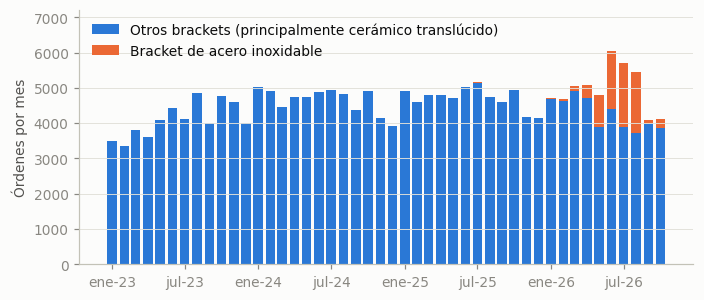

In [6]:
# Figura 1. Órdenes mensuales por tipo de bracket
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.bar(mensual.index, mensual["otros"], width=24, color=C["azul"], label="Otros brackets (principalmente cerámico translúcido)")
ax.bar(mensual.index, mensual["acero"], width=24, bottom=mensual["otros"], color=C["naranja"], label="Bracket de acero inoxidable")
ax.set(ylabel="Órdenes por mes", ylim=(0, 7200))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(FMT_MES)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=1)
fig.savefig("figuras/fig1_serie_mensual.png"); plt.show()

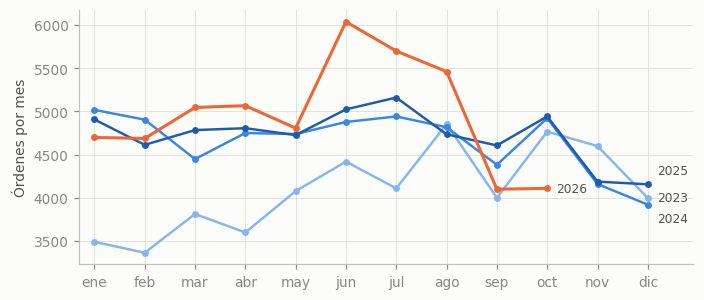

In [7]:
# Figura 2. Perfil anual: un trazo por año, para ver si el patrón por mes se repite
fig, ax = plt.subplots(figsize=(7.2, 3.0))
colores = {2023: C["azul_claro"], 2024: C["azul_medio"], 2025: C["azul_oscuro"], 2026: C["naranja"]}
for anio, g in serie.groupby(serie.index.year):
    ax.plot(g.index.month, g.values, color=colores[anio], lw=2 if anio == 2026 else 1.6, marker="o", ms=3.5)
    ax.annotate(str(anio), xy=(g.index.month[-1], g.values[-1]), xytext=(6, {2025: 9, 2023: 0, 2024: -9}.get(anio, 0)),
                textcoords="offset points", va="center", fontsize=8, color=C["tinta2"])
ax.set(ylabel="Órdenes por mes", xlim=(0.7, 12.9))
ax.set_xticks(range(1, 13)); ax.set_xticklabels(nombres_mes)
fig.savefig("figuras/fig2_perfil_anual.png"); plt.show()

Fuerza de la tendencia: 0.38 | Fuerza de la estacionalidad anual: 0.28
ACF rezago 1: 0.51 | 2: 0.32 | 6: -0.03 | 12: 0.15


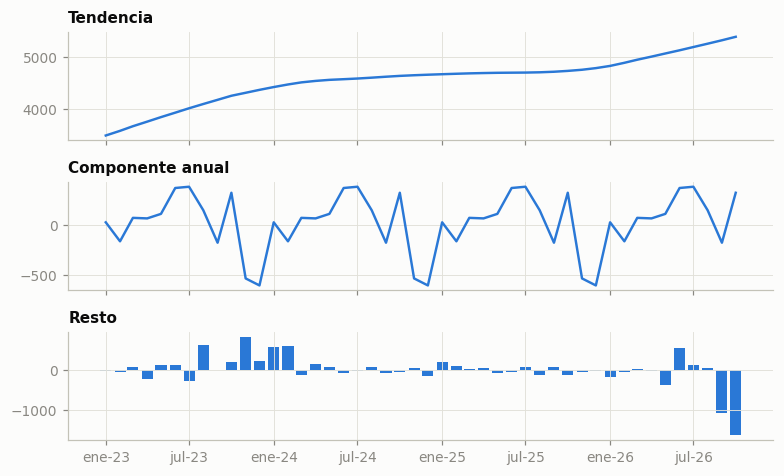

Resto de mayor magnitud: {'2026-10': -1614, '2026-09': -1058, '2023-11': 821, '2023-08': 614}


In [8]:
# Figura 3. Descomposición STL robusta con período 12 (tendencia, componente anual y resto)
# seasonal=99 con seasonal_deg=0: el componente anual es el mismo cada año, equivalente a season(window = "periodic") de fpp3
stl = STL(serie, period=12, seasonal=99, seasonal_deg=0, robust=True).fit()
Ft = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
Fs = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
print("Fuerza de la tendencia: %.2f | Fuerza de la estacionalidad anual: %.2f" % (Ft, Fs))
a = acf(serie, nlags=12)
print("ACF rezago 1: %.2f | 2: %.2f | 6: %.2f | 12: %.2f" % (a[1], a[2], a[6], a[12]))

fig, ax = plt.subplots(3, 1, figsize=(7.2, 4.4), sharex=True)
ax[0].plot(stl.trend, color=C["azul"], lw=1.6); ax[0].set_title("Tendencia")
ax[1].plot(stl.seasonal, color=C["azul"], lw=1.6); ax[1].set_title("Componente anual")
ax[2].bar(stl.resid.index, stl.resid.values, width=24, color=C["azul"]); ax[2].set_title("Resto")
ax[2].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax[2].xaxis.set_major_formatter(FMT_MES)
fig.tight_layout(); fig.savefig("figuras/fig3_stl.png"); plt.show()
print("Resto de mayor magnitud:", {k.strftime("%Y-%m"): round(v) for k, v in stl.resid[stl.resid.abs().nlargest(4).index].items()})

In [9]:
# Estacionariedad: ADF (H0: raíz unitaria; p bajo = estacionaria) y KPSS (H0: estacionaria; p bajo = no estacionaria)
# Nota: statsmodels acota el p-valor de KPSS al rango [0.01, 0.10].
for etiqueta, x in [("serie original (46 meses)", serie),
                    ("diferencia estacional (1 - B^12), 34 meses", serie.diff(12).dropna()),
                    ("(1 - B)(1 - B^12), 33 meses", serie.diff(12).diff().dropna())]:
    print("%-44s ADF p = %.4f | KPSS p = %.2f" % (etiqueta, adfuller(x, autolag="AIC")[1], kpss(x, nlags="auto")[1]))

serie original (46 meses)                    ADF p = 0.0020 | KPSS p = 0.02
diferencia estacional (1 - B^12), 34 meses   ADF p = 0.0256 | KPSS p = 0.08
(1 - B)(1 - B^12), 33 meses                  ADF p = 0.0000 | KPSS p = 0.10


## 4. Modelos y validación de ventana expansiva

Todos los modelos se evalúan igual: la primera ventana entrena con enero de 2023 a diciembre de 2024 (24 meses) y pronostica los 3 meses siguientes; luego se agrega un mes por ventana hasta pronosticar agosto a octubre de 2026. Son 20 ventanas y 60 pronósticos por modelo. En cada ventana cada modelo se vuelve a ajustar solo con los meses anteriores a su origen.

| Familia | Modelo | Idea |
|---|---|---|
| Referencias | Naive, SNAIVE | Repite el último mes / el mismo mes del año anterior |
| Suavizamiento exponencial | AutoETS | Error, tendencia y estacionalidad elegidos por AICc |
| ARIMA estacional | SARIMA (AutoARIMA, m = 12) | Órdenes por pruebas de raíz unitaria y AICc |
| Ajuste por días hábiles | SNAIVE_dh, AutoETS_dh, SARIMA_dh | Se modela $y_t / d_t$ (órdenes por día hábil) y se multiplica por $d_{T+h}$ |
| Regresión | Ridge | Tendencia lineal, mes del año y días hábiles; penalización elegida con validación temporal |
| Aditivo | Prophet | Tendencia por tramos y estacionalidad anual de Fourier |
| Fundación | Chronos-2, Chronos-2 + días hábiles | Preentrenado, sin ajuste; la segunda versión recibe los días hábiles como covariable conocida |
| Fundación | TimesFM 2.5 (200M) | Preentrenado, sin ajuste |

In [10]:
H, M, INI = 3, 12, 24
datos = pd.DataFrame({"unique_id": "ordenes", "ds": serie.index, "y": serie.values})
N_VENT = len(serie) - INI - H + 1
print("Ventanas:", N_VENT, "| primer origen:", serie.index[INI - 1].strftime("%Y-%m"), "| último mes pronosticado:", serie.index[-1].strftime("%Y-%m"))

clasicos = [Naive(alias="Naive"), SeasonalNaive(season_length=M, alias="SNAIVE"),
            AutoETS(season_length=M, alias="AutoETS"), AutoARIMA(season_length=M, alias="SARIMA")]
cv = StatsForecast(models=clasicos, freq="MS", n_jobs=1).cross_validation(df=datos, h=H, step_size=1, n_windows=N_VENT, refit=True)
assert cv.cutoff.nunique() == N_VENT and cv.cutoff.min() == serie.index[INI - 1]

# Ajuste por días hábiles: el mismo modelo sobre órdenes por día hábil, y de vuelta a órdenes del mes.
# Se guardan también los intervalos del 80 % y 95 % de cada modelo para medir su cobertura (sección 7).
NIVELES = ["-lo-80", "-hi-80", "-lo-95", "-hi-95"]
cv_dh = StatsForecast(models=clasicos[1:], freq="MS", n_jobs=1).cross_validation(
    df=datos.assign(y=serie.values / dh.values), h=H, step_size=1, n_windows=N_VENT, refit=True, level=[80, 95])
for nom in ["SNAIVE", "AutoETS", "SARIMA"]:
    for sufijo in [""] + NIVELES:
        cv[nom + "_dh" + sufijo] = cv_dh[nom + sufijo].values * dh.reindex(cv_dh.ds).values

Ventanas: 20 | primer origen: 2024-12 | último mes pronosticado: 2026-10


In [11]:
def X_ridge(idx):
    t = np.array([(d.year - 2023) * 12 + d.month for d in idx], float)
    mes = pd.get_dummies(pd.Categorical([d.month for d in idx], categories=range(1, 13))).values[:, 1:].astype(float)
    return np.column_stack([t, mes, dias_habiles(idx)])

def ridge_fc(tr, fut):
    m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30), cv=TimeSeriesSplit(4)))
    m.fit(X_ridge(tr.index), tr.values)
    return m.predict(X_ridge(fut))

def prophet_fc(tr, fut):
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    m.fit(pd.DataFrame({"ds": tr.index, "y": tr.values}))
    return m.predict(pd.DataFrame({"ds": fut}))["yhat"].values

chronos2 = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu")
def chronos_fc(tr, fut, cov=False):
    ctx = pd.DataFrame({"id": "o", "timestamp": tr.index, "target": tr.values.astype(float)})
    fut_df = None
    if cov:
        ctx["dh"] = dias_habiles(tr.index).astype(float)
        fut_df = pd.DataFrame({"id": "o", "timestamp": fut, "dh": dias_habiles(fut).astype(float)})
    out = chronos2.predict_df(ctx, future_df=fut_df, prediction_length=len(fut), quantile_levels=[0.1, 0.5, 0.9],
                              id_column="id", timestamp_column="timestamp", target="target")
    return out["0.5"].values

tfm = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
tfm.compile(timesfm.ForecastConfig(max_context=1024, max_horizon=64, normalize_inputs=True, use_continuous_quantile_head=True,
                                   force_flip_invariance=True, infer_is_positive=True, fix_quantile_crossing=True))
def timesfm_fc(tr, fut):
    punto, _ = tfm.forecast(horizon=len(fut), inputs=[tr.values.astype(float)])
    return punto[0]

otros = {"Ridge": ridge_fc, "Prophet": prophet_fc, "Chronos2": chronos_fc,
         "Chronos2_dh": lambda tr, fut: chronos_fc(tr, fut, cov=True), "TimesFM": timesfm_fc}
for nom, f in otros.items():
    partes = [pd.Series(f(serie[:corte], pd.DatetimeIndex(g.ds)), index=g.index) for corte, g in cv.groupby("cutoff", sort=True)]
    cv[nom] = pd.concat(partes)

NOMBRES = ["Naive", "SNAIVE", "AutoETS", "SARIMA", "SNAIVE_dh", "AutoETS_dh", "SARIMA_dh",
           "Ridge", "Prophet", "Chronos2", "Chronos2_dh", "TimesFM"]
for col in [c for c in cv.columns if c.split("-")[0] in NOMBRES]:
    cv[col] = cv[col].clip(lower=0)                                    # restricción: los conteos no son negativos
cv["h"] = cv.groupby("cutoff").cumcount() + 1
print("Pronósticos evaluados por modelo:", len(cv), "(", cv.cutoff.nunique(), "ventanas x", H, "meses )")

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Pronósticos evaluados por modelo: 60 ( 20 ventanas x 3 meses )


## 5. Resultados de la validación

In [12]:
def escala_mase(corte):
    """Error absoluto medio del ingenuo estacional (m = 12) dentro del entrenamiento hasta `corte`."""
    ent = serie[:corte].values
    return np.mean(np.abs(ent[M:] - ent[:-M]))

cv["esc"] = cv.cutoff.map(escala_mase)
QUIEBRE = pd.Timestamp("2026-03-01")            # orígenes desde marzo de 2026: pronostican meses con el producto de acero
mase_v = pd.DataFrame({n: ((cv.y - cv[n]).abs() / cv.esc).groupby(cv.cutoff).mean() for n in NOMBRES})   # MASE por ventana
pre = mase_v.index < QUIEBRE
filas = []
for n in NOMBRES:
    e = cv.y - cv[n]
    por_h = (e.abs() / cv.esc).groupby(cv.h).mean()
    filas.append({"modelo": n, "MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "MASE": mase_v[n].mean(),
                  "MASE antes mar-26": mase_v[n][pre].mean(), "MASE desde mar-26": mase_v[n][~pre].mean(),
                  "h=1": por_h[1], "h=2": por_h[2], "h=3": por_h[3],
                  "gana a SNAIVE": int((mase_v[n] < mase_v.SNAIVE).sum()) if n != "SNAIVE" else np.nan,
                  "p Wilcoxon vs SNAIVE": wilcoxon(mase_v[n], mase_v.SNAIVE).pvalue if n != "SNAIVE" else np.nan,
                  "sesgo": (cv[n] - cv.y).mean()})
tabla = pd.DataFrame(filas).set_index("modelo").sort_values("MASE")
print("Ventanas: %d en total, %d con origen antes de marzo de 2026 y %d desde marzo de 2026" % (len(mase_v), pre.sum(), (~pre).sum()))
print(tabla.round(3).to_string())
MEJOR = tabla.index[0]
print("\nMejor modelo por MASE promedio:", MEJOR)
print("%s contra SARIMA_dh: gana en %d de %d ventanas | Wilcoxon p = %.3f" %
      (MEJOR, (mase_v[MEJOR] < mase_v.SARIMA_dh).sum(), len(mase_v), wilcoxon(mase_v[MEJOR], mase_v.SARIMA_dh).pvalue))

Ventanas: 20 en total, 15 con origen antes de marzo de 2026 y 5 desde marzo de 2026
                 MAE     RMSE   MASE  MASE antes mar-26  MASE desde mar-26    h=1    h=2    h=3  gana a SNAIVE  p Wilcoxon vs SNAIVE    sesgo
modelo                                                                                                                                       
SNAIVE_dh    234.558  329.645  0.564              0.246              1.519  0.506  0.558  0.628           14.0                 0.008 -162.769
SARIMA_dh    283.453  414.594  0.633              0.426              1.252  0.419  0.613  0.866            8.0                 0.546  -48.982
SNAIVE       268.667  374.445  0.646              0.325              1.608  0.588  0.636  0.714            NaN                   NaN -153.733
SARIMA       306.823  492.002  0.700              0.392              1.621  0.513  0.708  0.877           10.0                 0.756  -48.493
Ridge        301.143  387.999  0.711              0.503         

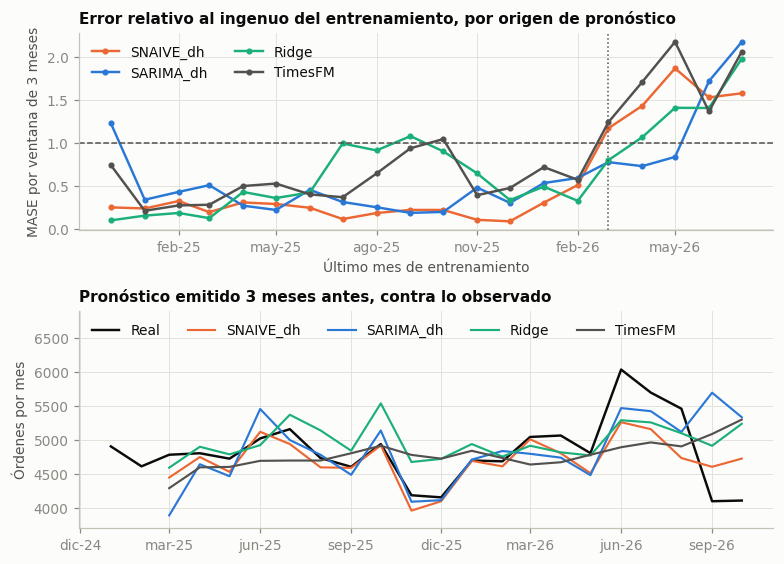

In [13]:
# Figura 5. MASE por ventana de los mejores modelos de cada familia y pronóstico emitido 3 meses antes
vista = {"SNAIVE_dh": C["naranja"], "SARIMA_dh": C["azul"], "Ridge": C["aqua"], "TimesFM": C["tinta2"]}
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 5.2), gridspec_kw={"height_ratios": [1, 1.1]})
for n, col in vista.items():
    a1.plot(mase_v.index, mase_v[n], color=col, lw=1.6, marker="o", ms=3, label=n)
a1.axhline(1, color=C["tinta2"], lw=1, ls="--")
a1.axvline(QUIEBRE, color=C["tinta2"], lw=1, ls=":")
a1.set(ylabel="MASE por ventana de 3 meses", title="Error relativo al ingenuo del entrenamiento, por origen de pronóstico",
       xlabel="Último mes de entrenamiento")
a1.legend(loc="upper left", ncol=2)
a1.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); a1.xaxis.set_major_formatter(FMT_MES)

h3 = cv[cv.h == H].set_index("ds")                                        # el tercer mes de cada ventana
a2.plot(serie["2025-01":].index, serie["2025-01":].values, color=C["tinta"], lw=1.6, label="Real")
for n, col in vista.items():
    a2.plot(h3.index, h3[n], color=col, lw=1.4, label=n)
a2.set(ylabel="Órdenes por mes", title="Pronóstico emitido 3 meses antes, contra lo observado", ylim=(3700, 6900))
a2.legend(loc="upper left", ncol=5)
a2.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); a2.xaxis.set_major_formatter(FMT_MES)
fig.tight_layout(); fig.savefig("figuras/fig5_validacion_mensual.png"); plt.show()

## 6. Variable de intervención del acero

El auge y la pausa del acero de 2026 fueron decisiones de capacidad de la empresa. Aquí se modelan con una **variable de intervención**: la proporción de acero del mes, $x_t = \text{acero}_t / y_t$, que vale casi 0 hasta febrero de 2026, sube a cerca de 0.3 en julio y agosto y baja otra vez en septiembre y octubre, cuando se pausó el producto. A diferencia de una indicadora 0/1, $x_t$ mide también la velocidad de adopción.

| Modelo | Ecuación |
|---|---|
| SARIMAX_dh | $r_t = y_t/d_t = \beta\,x_t + \eta_t$, con $\eta_t$ un SARIMA elegido por AutoARIMA (regresión con errores ARIMA); $\hat y_{T+h} = d_{T+h}\,\hat r_{T+h}$ |
| Ridge_ac | La regresión Ridge de la sección 4 con $x_t$ como columna adicional |
| Chronos2_ac | Chronos-2 con $d_t$ y $x_t$ como covariables conocidas en el horizonte |

**Cómo se construye $x_{T+h}$ en el horizonte.** Sus valores futuros no se observan al emitir el pronóstico, así que se comparan dos construcciones:

- *Persistencia* (sin información adicional): $x_{T+h} = x_T$, la proporción del último mes observado.
- *Plan de capacidad*: el valor que corresponde a la decisión de capacidad vigente. La empresa decide con anticipación cuándo abre o cierra la recepción de acero (el cierre de inicios de septiembre y la reapertura del 26 de octubre de 2026 se comunicaron antes de aplicarse), así que quien pronostica conoce el estado del acero en el horizonte. En la validación se usa la proporción realizada como aproximación de ese plan. Es una cota optimista, porque además del estado abierto o cerrado incluye la velocidad real de adopción.

La intervención solo entra cuando $x_t$ ya varía en el entrenamiento (desviación estándar mayor que 0.01, lo que ocurre desde los orígenes de 2026). Antes de eso cada modelo coincide con su versión sin intervención.

In [14]:
pac = mensual["prop_acero"].astype(float)
ESCENARIOS = ["pers", "plan"]
print("Proporción de acero por mes desde enero de 2026:", pac["2026-01":].round(3).to_dict())

def x_futuro(corte, fut, esc):
    """Proporción de acero en el horizonte: persistencia del último mes o plan de capacidad (en la validación, la realizada)."""
    return np.full(len(fut), pac[corte]) if esc == "pers" else pac.reindex(fut).values

def activa(tr_idx):
    return pac[tr_idx].std() > 0.01

def sarimax_dh_fc(tr_idx, fut, xf):
    """SARIMA sobre órdenes por día hábil con la proporción de acero como regresor; devuelve punto e intervalos en órdenes."""
    df = pd.DataFrame({"unique_id": "o", "ds": tr_idx, "y": (serie[tr_idx] / dh[tr_idx]).values})
    X_df = None
    if activa(tr_idx):
        df["acero"] = pac[tr_idx].values
        X_df = pd.DataFrame({"unique_id": "o", "ds": fut, "acero": xf})
    f = StatsForecast(models=[AutoARIMA(season_length=M, alias="m")], freq="MS").forecast(df=df, h=len(fut), X_df=X_df, level=[80, 95])
    return {s_: np.clip(f["m" + s_].values * dias_habiles(fut), 0, None) for s_ in [""] + NIVELES}

def ridge_ac_fc(tr_idx, fut, xf):
    Xtr, Xfu = X_ridge(tr_idx), X_ridge(fut)
    if activa(tr_idx):
        Xtr, Xfu = np.column_stack([Xtr, pac[tr_idx].values]), np.column_stack([Xfu, xf])
    m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30), cv=TimeSeriesSplit(4)))
    return np.clip(m.fit(Xtr, serie[tr_idx].values).predict(Xfu), 0, None)

def chronos_ac_fc(tr_idx, fut, xf):
    ctx = pd.DataFrame({"id": "o", "timestamp": tr_idx, "target": serie[tr_idx].values,
                        "dh": dh[tr_idx].values, "acero": pac[tr_idx].values})
    fdf = pd.DataFrame({"id": "o", "timestamp": fut, "dh": dias_habiles(fut).astype(float), "acero": xf})
    out = chronos2.predict_df(ctx, future_df=fdf, prediction_length=len(fut), quantile_levels=[0.1, 0.5, 0.9],
                              id_column="id", timestamp_column="timestamp", target="target")
    return np.clip(out["0.5"].values, 0, None)

for corte, g in cv.groupby("cutoff", sort=True):
    tr_idx, fut_v = serie[:corte].index, pd.DatetimeIndex(g.ds)
    for esc in ESCENARIOS:
        xf = x_futuro(corte, fut_v, esc)
        for s_, v in sarimax_dh_fc(tr_idx, fut_v, xf).items():
            cv.loc[g.index, "SARIMAX_dh_" + esc + s_] = v
        cv.loc[g.index, "Ridge_ac_" + esc] = ridge_ac_fc(tr_idx, fut_v, xf)
        cv.loc[g.index, "Chronos2_ac_" + esc] = chronos_ac_fc(tr_idx, fut_v, xf)

INTERV = [m + "_" + e for m in ["SARIMAX_dh", "Ridge_ac", "Chronos2_ac"] for e in ESCENARIOS]
for n in INTERV:
    mase_v[n] = ((cv.y - cv[n]).abs() / cv.esc).groupby(cv.cutoff).mean()
comparar = ["SNAIVE_dh", "SARIMA_dh", "Ridge", "Chronos2_dh"] + INTERV
tabla_int = pd.DataFrame({n: {"MASE": mase_v[n].mean(), "MASE antes mar-26": mase_v[n][pre].mean(),
                              "MASE desde mar-26": mase_v[n][~pre].mean(),
                              "gana a SNAIVE_dh": (mase_v[n] < mase_v.SNAIVE_dh).sum() if n != "SNAIVE_dh" else np.nan,
                              "p vs SNAIVE_dh": wilcoxon(mase_v[n], mase_v.SNAIVE_dh).pvalue if n != "SNAIVE_dh" else np.nan,
                              "sesgo desde mar-26": (cv[n] - cv.y)[cv.cutoff >= QUIEBRE].mean()} for n in comparar}).T
print(tabla_int.astype(float).round(3).to_string())
print()
for base_, n in [("SARIMA_dh", "SARIMAX_dh_pers"), ("SARIMA_dh", "SARIMAX_dh_plan"), ("Ridge", "Ridge_ac_plan"), ("Chronos2_dh", "Chronos2_ac_plan")]:
    print("%-16s frente a %-11s ventanas desde marzo de 2026: MASE %.2f -> %.2f | gana en %d de %d" %
          (n, base_, mase_v[base_][~pre].mean(), mase_v[n][~pre].mean(), (mase_v[n][~pre] < mase_v[base_][~pre]).sum(), (~pre).sum()))

Proporción de acero por mes desde enero de 2026: {Timestamp('2026-01-01 00:00:00'): 0.004, Timestamp('2026-02-01 00:00:00'): 0.013, Timestamp('2026-03-01 00:00:00'): 0.024, Timestamp('2026-04-01 00:00:00'): 0.07, Timestamp('2026-05-01 00:00:00'): 0.19, Timestamp('2026-06-01 00:00:00'): 0.269, Timestamp('2026-07-01 00:00:00'): 0.32, Timestamp('2026-08-01 00:00:00'): 0.319, Timestamp('2026-09-01 00:00:00'): 0.029, Timestamp('2026-10-01 00:00:00'): 0.058}


                   MASE  MASE antes mar-26  MASE desde mar-26  gana a SNAIVE_dh  p vs SNAIVE_dh  sesgo desde mar-26
SNAIVE_dh         0.564              0.246              1.519               NaN             NaN            -356.386
SARIMA_dh         0.633              0.426              1.252               7.0           0.143             100.293
Ridge             0.711              0.503              1.336               9.0           0.231            -135.428
Chronos2_dh       0.908              0.601              1.830               1.0           0.000            -227.086
SARIMAX_dh_pers   0.615              0.426              1.181               8.0           0.312              43.850
SARIMAX_dh_plan   0.543              0.426              0.895               9.0           0.622             119.162
Ridge_ac_pers     0.700              0.503              1.289               9.0           0.277              55.028
Ridge_ac_plan     0.631              0.503              1.014           

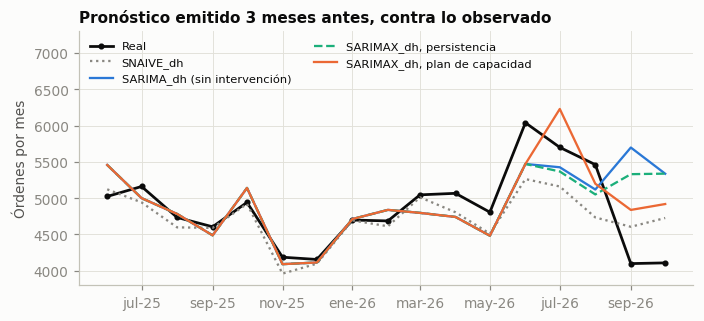

In [15]:
# Figura 6. Pronóstico del tercer mes emitido en cada origen, con y sin la variable de intervención
fig, ax = plt.subplots(figsize=(7.2, 3.0))
h3 = cv[cv.h == H].set_index("ds")
ax.plot(serie["2025-06":].index, serie["2025-06":].values, color=C["tinta"], lw=1.8, marker="o", ms=3, label="Real")
for n, col, ls, et in [("SNAIVE_dh", C["tenue"], ":", "SNAIVE_dh"),
                       ("SARIMA_dh", C["azul"], "-", "SARIMA_dh (sin intervención)"),
                       ("SARIMAX_dh_pers", C["aqua"], "--", "SARIMAX_dh, persistencia"),
                       ("SARIMAX_dh_plan", C["naranja"], "-", "SARIMAX_dh, plan de capacidad")]:
    ax.plot(h3["2025-06":].index, h3["2025-06":][n], color=col, lw=1.5, ls=ls, label=et)
ax.set(ylabel="Órdenes por mes", title="Pronóstico emitido 3 meses antes, contra lo observado", ylim=(3800, 7300))
ax.legend(loc="upper left", ncol=2, fontsize=7.5)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(FMT_MES)
fig.savefig("figuras/fig6_intervencion.png"); plt.show()

## 7. Cobertura de los intervalos

Un intervalo del 80 % debería contener el valor real en cerca del 80 % de los pronósticos. Se mide esa **cobertura** en los 60 pronósticos de la validación, para los intervalos propios de cada modelo (ETS, SARIMA, SARIMAX e ingenuo estacional: fórmula del modelo; Chronos-2 y TimesFM: sus cuantiles; Prophet: simulación de su incertidumbre) y para el **intervalo empírico** del avance (cuantiles del cociente real/pronóstico). Para que el empírico no use información del futuro, en cada origen se calcula solo con los errores de meses ya observados en ese origen y se exige un mínimo de 6 errores por horizonte, así que se evalúa en menos pronósticos. TimesFM entrega deciles, así que solo tiene intervalo del 80 %.

In [16]:
for corte, g in cv.groupby("cutoff", sort=True):
    tr, fut_v = serie[:corte], pd.DatetimeIndex(g.ds)
    ctx = pd.DataFrame({"id": "o", "timestamp": tr.index, "target": tr.values, "dh": dh[tr.index].values})
    fdf = pd.DataFrame({"id": "o", "timestamp": fut_v, "dh": dias_habiles(fut_v).astype(float)})
    q = chronos2.predict_df(ctx, future_df=fdf, prediction_length=len(fut_v), quantile_levels=[0.025, 0.1, 0.9, 0.975],
                            id_column="id", timestamp_column="timestamp", target="target")
    for s_, c in zip(NIVELES, ["0.1", "0.9", "0.025", "0.975"]):
        cv.loc[g.index, "Chronos2_dh" + s_] = q[c].values
    _, qt = tfm.forecast(horizon=len(fut_v), inputs=[tr.values.astype(float)])
    cv.loc[g.index, "TimesFM-lo-80"], cv.loc[g.index, "TimesFM-hi-80"] = qt[0][:, 1], qt[0][:, 9]   # deciles 1 y 9
    mp = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    mp.fit(pd.DataFrame({"ds": tr.index, "y": tr.values}))
    sim = mp.predictive_samples(pd.DataFrame({"ds": fut_v}))["yhat"]
    for s_, qq in zip(NIVELES, [0.1, 0.9, 0.025, 0.975]):
        cv.loc[g.index, "Prophet" + s_] = np.quantile(sim, qq, axis=1)

def empirico_secuencial(n, nivel, minimo=6):
    """Intervalo empírico con solo los errores de meses ya observados en cada origen."""
    a = (1 - nivel / 100) / 2
    lo, hi = pd.Series(np.nan, index=cv.index), pd.Series(np.nan, index=cv.index)
    for i in cv.index:
        prev = cv[(cv.ds <= cv.cutoff[i]) & (cv.h == cv.h[i])]
        if len(prev) >= minimo:
            r = prev.y / prev[n]
            lo[i], hi[i] = cv[n][i] * r.quantile(a), cv[n][i] * r.quantile(1 - a)
    return lo, hi

for nivel in [80, 95]:
    cv["SNAIVE_dh_emp-lo-%d" % nivel], cv["SNAIVE_dh_emp-hi-%d" % nivel] = empirico_secuencial("SNAIVE_dh", nivel)

INTERVALOS = [("SNAIVE_dh_emp", "SNAIVE_dh, empírico"), ("SNAIVE_dh", "SNAIVE_dh, del modelo"), ("SARIMA_dh", "SARIMA_dh"),
              ("SARIMAX_dh_plan", "SARIMAX_dh, plan"), ("AutoETS_dh", "AutoETS_dh"), ("Prophet", "Prophet"),
              ("Chronos2_dh", "Chronos-2_dh"), ("TimesFM", "TimesFM 2.5")]
filas = []
for n, et in INTERVALOS:
    fila = {"intervalo": et}
    for nivel in [80, 95]:
        lo_c, hi_c = "%s-lo-%d" % (n, nivel), "%s-hi-%d" % (n, nivel)
        if lo_c not in cv:
            continue
        ok = cv[lo_c].notna()
        dentro = (cv.y >= cv[lo_c]) & (cv.y <= cv[hi_c])
        fila["n"] = ok.sum()
        fila["cob %d" % nivel] = dentro[ok].mean()
        fila["cob %d antes" % nivel] = dentro[ok & (cv.cutoff < QUIEBRE)].mean()
        fila["cob %d desde" % nivel] = dentro[ok & (cv.cutoff >= QUIEBRE)].mean()
        fila["ancho %d (%%)" % nivel] = 100 * ((cv[hi_c] - cv[lo_c]) / cv[n.replace("_emp", "")])[ok].mean()
    filas.append(fila)
cobertura = pd.DataFrame(filas).set_index("intervalo")
print("Cobertura observada en la validación (proporción de pronósticos con el valor real dentro del intervalo);")
print("ancho = ancho medio del intervalo como % del pronóstico puntual")
print(cobertura.astype(float).round(2).to_string())

Cobertura observada en la validación (proporción de pronósticos con el valor real dentro del intervalo);
ancho = ancho medio del intervalo como % del pronóstico puntual
                          n  cob 80  cob 80 antes  cob 80 desde  ancho 80 (%)  cob 95  cob 95 antes  cob 95 desde  ancho 95 (%)
intervalo                                                                                                                      
SNAIVE_dh, empírico    39.0    0.54          0.88          0.00          6.91    0.72          1.00          0.27          9.62
SNAIVE_dh, del modelo  60.0    0.90          1.00          0.60         32.86    1.00          1.00          1.00         50.26
SARIMA_dh              60.0    0.83          0.91          0.60         19.31    0.93          0.98          0.80         29.53
SARIMAX_dh, plan       60.0    0.83          0.91          0.60         19.17    0.93          0.98          0.80         29.31
AutoETS_dh             60.0    0.72          0.80          0.47

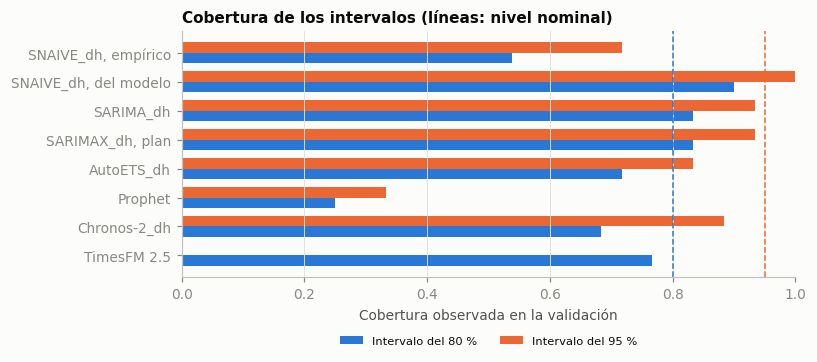

In [17]:
# Figura 7. Cobertura observada contra la nominal
fig, ax = plt.subplots(figsize=(7.2, 2.9))
yy = np.arange(len(cobertura))
ax.barh(yy + 0.18, cobertura["cob 80"], height=0.36, color=C["azul"], label="Intervalo del 80 %")
ax.barh(yy - 0.18, cobertura["cob 95"], height=0.36, color=C["naranja"], label="Intervalo del 95 %")
for v, col in [(0.80, C["azul"]), (0.95, C["naranja"])]:
    ax.axvline(v, color=col, lw=1, ls="--")
ax.set_yticks(yy); ax.set_yticklabels(cobertura.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set(xlabel="Cobertura observada en la validación", xlim=(0, 1), title="Cobertura de los intervalos (líneas: nivel nominal)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=7.5)
fig.savefig("figuras/fig7_cobertura_mensual.png"); plt.show()

## 8. Diagnóstico del SARIMA y pronóstico de noviembre de 2026 a enero de 2027

In [18]:
def texto_orden(modelo):
    p, q, P, Q, m_, d, D = modelo.model_["arma"]             # convención de statsforecast: (p, q, P, Q, m, d, D)
    return "(%d,%d,%d)(%d,%d,%d)[%d]" % (p, d, q, P, D, Q, m_)

# Órdenes que AutoARIMA eligió para SARIMA_dh en cada ventana (solo con datos anteriores al origen)
datos_dh = datos.assign(y=serie.values / dh.values)
elegidos = []
for k in range(INI, len(datos) - H + 1):
    sf_k = StatsForecast(models=[AutoARIMA(season_length=M)], freq="MS").fit(datos_dh.iloc[:k])
    elegidos.append(texto_orden(sf_k.fitted_[0, 0]))
print("Órdenes elegidos para SARIMA_dh en las %d ventanas:" % N_VENT)
print(pd.Series(elegidos).value_counts().to_string())

# Ajuste con los 46 meses y diagnóstico de residuos
sf_sar = StatsForecast(models=[AutoARIMA(season_length=M, alias="SARIMA_dh")], freq="MS").fit(datos_dh)
modelo_fin = sf_sar.fitted_[0, 0]
p_, q_, P_, Q_, _, d_, D_ = [int(v) for v in modelo_fin.model_["arma"]]
k0 = d_ + D_ * M                                                   # los primeros k0 residuos se pierden al diferenciar
res = pd.Series(modelo_fin.model_["residuals"][k0:] * dh.values[k0:], index=serie.index[k0:])   # en órdenes por mes
lb = acorr_ljungbox(res, lags=[6, 12], model_df=p_ + q_ + P_ + Q_)
print("\nSARIMA_dh con los 46 meses: SARIMA" + texto_orden(modelo_fin), "| residuos: n = %d" % len(res))
print("Ljung-Box (gl ajustados por %d parámetros ARMA):" % (p_ + q_ + P_ + Q_))
print(lb.round(3).to_string())

Órdenes elegidos para SARIMA_dh en las 20 ventanas:
(0,1,0)(0,1,0)[12]    11
(0,1,0)(1,1,0)[12]     5
(0,1,0)(0,1,1)[12]     2
(1,1,0)(0,0,0)[12]     1
(0,2,1)(1,1,0)[12]     1

SARIMA_dh con los 46 meses: SARIMA(0,1,0)(0,1,0)[12] | residuos: n = 33
Ljung-Box (gl ajustados por 0 parámetros ARMA):
    lb_stat  lb_pvalue
6     6.231      0.398
12    9.236      0.683


In [19]:
# Pronóstico final: cada modelo se ajusta con los 46 meses (enero de 2023 a octubre de 2026)
fut = pd.date_range(serie.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")
dh_fut = dias_habiles(fut).astype(float)
fin = pd.DataFrame(index=fut)
f_cl = StatsForecast(models=clasicos, freq="MS").forecast(df=datos, h=H)
f_dh = StatsForecast(models=clasicos[1:], freq="MS").forecast(df=datos_dh, h=H, level=[80, 95])
for n in ["Naive", "SNAIVE", "AutoETS", "SARIMA"]:
    fin[n] = f_cl[n].values
for n in ["SNAIVE", "AutoETS", "SARIMA"]:
    fin[n + "_dh"] = f_dh[n].values * dh_fut
ic = {n + "_dh": {s_: f_dh[n + s_].values * dh_fut for s_ in NIVELES} for n in ["SNAIVE", "SARIMA"]}   # intervalos del modelo
for n, f in otros.items():
    fin[n] = f(serie, fut)
fin = fin[NOMBRES].clip(lower=0)

# Escenarios de la variable de intervención para noviembre a enero
reap = diario["2026-10-26":]
X_ESC = {"pers": pac.iloc[-1],                                   # proporción de octubre (acero cerrado casi todo el mes)
         "reap": reap.acero.sum() / reap.ordenes.sum()}          # proporción observada desde la reapertura del 26 de octubre
print("Proporción de acero, octubre: %.3f | desde la reapertura (26 de octubre al %s): %.3f" %
      (X_ESC["pers"], reap.index[-1].strftime("%d de noviembre"), X_ESC["reap"]))
for esc, x in X_ESC.items():
    sx = sarimax_dh_fc(serie.index, fut, np.full(H, x))
    fin["SARIMAX_dh_" + esc], ic["SARIMAX_dh_" + esc] = sx[""], sx
    fin["Chronos2_ac_" + esc] = chronos_ac_fc(serie.index, fut, np.full(H, x))
    fin["Ridge_ac_" + esc] = ridge_ac_fc(serie.index, fut, np.full(H, x))

# Intervalos: los del propio modelo, que en la sección 7 tuvieron cobertura igual o mayor que la nominal
# (el intervalo empírico del avance resultó demasiado angosto y no se usa)
tab = pd.DataFrame(index=fut.strftime("%Y-%m"))
for n, niveles in [(MEJOR, [80, 95]), ("SARIMA_dh", [80]), ("SARIMAX_dh_pers", [80]), ("SARIMAX_dh_reap", [80])]:
    tab[n] = fin[n].round().astype(int).values
    for nv in niveles:
        tab[n + " (%d %%)" % nv] = ["%d a %d" % (a, b) for a, b in zip(ic[n]["-lo-%d" % nv].round(), ic[n]["-hi-%d" % nv].round())]
print(tab.to_string())
print("Totales del trimestre:", fin.sum().round().astype(int).to_dict())
print("Días hábiles:", dict(zip(fut.strftime("%Y-%m"), dh_fut.astype(int))))

Proporción de acero, octubre: 0.058 | desde la reapertura (26 de octubre al 11 de noviembre): 0.258


         SNAIVE_dh SNAIVE_dh (80 %) SNAIVE_dh (95 %)  SARIMA_dh SARIMA_dh (80 %)  SARIMAX_dh_pers SARIMAX_dh_pers (80 %)  SARIMAX_dh_reap SARIMAX_dh_reap (80 %)
2026-11       4396      3739 a 5054      3391 a 5402       3806      3400 a 4213             3701            3426 a 3975             4431            4156 a 4705
2026-12       4156      3436 a 4876      3055 a 5257       3510      2881 a 4139             3487            3062 a 3911             4286            3861 a 4711
2027-01       4485      3828 a 5143      3480 a 5491       3895      3192 a 4599             3894            3418 a 4369             4624            4148 a 5099
Totales del trimestre: {'Naive': 12327, 'SNAIVE': 13042, 'AutoETS': 14447, 'SARIMA': 11361, 'SNAIVE_dh': 13038, 'AutoETS_dh': 12144, 'SARIMA_dh': 11211, 'Ridge': 14269, 'Prophet': 14071, 'Chronos2': 12616, 'Chronos2_dh': 12710, 'TimesFM': 12764, 'SARIMAX_dh_pers': 11081, 'Chronos2_ac_pers': 11841, 'Ridge_ac_pers': 14238, 'SARIMAX_dh_reap': 13340, 'Chrono

Noviembre 1 al 11: 2026 = 2033 órdenes (8 días hábiles) | 2025 = 1645 (7 días hábiles)
Ritmo por día hábil 2026 / 2025: 1.081
SNAIVE_dh de noviembre: 4396 | ajustado por el ritmo observado: 4754


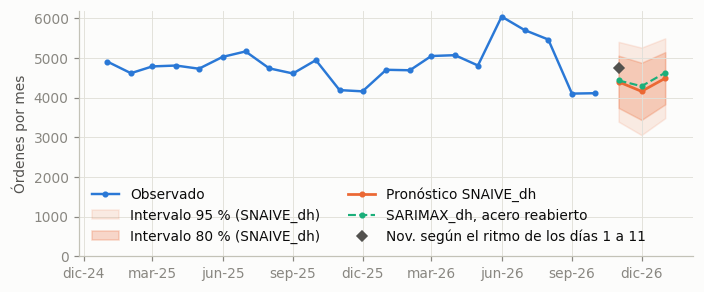

In [20]:
# Contraste con lo ya observado en noviembre de 2026 (ritmo de los primeros días contra los mismos días de 2025)
n_dias = nov_parcial.index[-1].day
obs26 = nov_parcial.ordenes.sum()
obs25 = diario["2025-11-01":"2025-11-%02d" % n_dias].ordenes.sum()
bd26 = np.busday_count("2026-11-01", (nov_parcial.index[-1] + pd.Timedelta(days=1)).date())
bd25 = np.busday_count("2025-11-01", "2025-11-%02d" % (n_dias + 1))
ritmo = (obs26 / bd26) / (obs25 / bd25)
print("Noviembre 1 al %d: 2026 = %d órdenes (%d días hábiles) | 2025 = %d (%d días hábiles)" % (n_dias, obs26, bd26, obs25, bd25))
print("Ritmo por día hábil 2026 / 2025: %.3f" % ritmo)
print("%s de noviembre: %d | ajustado por el ritmo observado: %d" % (MEJOR, fin.loc["2026-11-01", MEJOR], fin.loc["2026-11-01", MEJOR] * ritmo))

# Figura 8. Pronóstico de noviembre de 2026 a enero de 2027
fig, ax = plt.subplots(figsize=(7.2, 2.9))
hist = serie["2025-01":]
ax.plot(hist.index, hist.values, color=C["azul"], lw=1.6, marker="o", ms=3, label="Observado")
ax.fill_between(fut, ic[MEJOR]["-lo-95"], ic[MEJOR]["-hi-95"], color=C["naranja"], alpha=0.12, label="Intervalo 95 % (" + MEJOR + ")")
ax.fill_between(fut, ic[MEJOR]["-lo-80"], ic[MEJOR]["-hi-80"], color=C["naranja"], alpha=0.25, label="Intervalo 80 % (" + MEJOR + ")")
ax.plot(fut, fin[MEJOR], color=C["naranja"], lw=1.8, marker="o", ms=3, label="Pronóstico " + MEJOR)
ax.plot(fut, fin["SARIMAX_dh_reap"], color=C["aqua"], lw=1.4, marker="o", ms=3, ls="--", label="SARIMAX_dh, acero reabierto")
ax.plot([fut[0]], [fin.loc[fut[0], MEJOR] * ritmo], marker="D", ms=5, color=C["tinta2"], ls="none",
        label="Nov. según el ritmo de los días 1 a %d" % n_dias)
ax.set(ylabel="Órdenes por mes", ylim=(0, None)); ax.legend(loc="lower left", ncol=2)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)); ax.xaxis.set_major_formatter(FMT_MES)
fig.savefig("figuras/fig8_pronostico_mensual.png"); plt.show()

## 9. Conclusiones

1. **El método 1, el ingenuo estacional ajustado por días hábiles (SNAIVE_dh), es el mejor modelo mensual.** Tiene el MASE promedio más bajo (0.56) y supera al ingenuo estacional simple en 14 de 20 ventanas (Wilcoxon p = 0.008). Frente a SARIMA_dh (0.63) gana en 13 de 20, pero la diferencia no es significativa (p = 0.14).
2. **El método 2, Chronos-2, no supera a las referencias clásicas a escala mensual** (0.91 con la covariable de días hábiles), y tampoco aprovecha la covariable de acero (1.83 → 1.79 desde marzo de 2026). Con 24 a 43 meses de contexto y un patrón anual estable, repetir el año anterior ya captura casi todo.
3. **La variable de intervención del acero sirve si se conoce el plan de capacidad.** Desde marzo de 2026, SARIMAX_dh con el plan baja el MASE de SARIMA_dh de 1.25 a 0.89 (y el promedio total a 0.543, el más bajo de todos) y Ridge con la intervención baja de 1.34 a 1.01. Con persistencia de la última proporción la mejora es mínima (1.25 → 1.18): la pausa de septiembre no se podía anticipar con la proporción de agosto.
4. **Cobertura:** el intervalo empírico de SNAIVE_dh subcubre (54 % y 72 % para los niveles del 80 % y 95 %) porque se calibró con los errores pequeños de 2025. El intervalo del propio modelo cubre el 90 % y 100 %, conservador, y el de SARIMA_dh el 83 % y 93 %, el más cercano al nominal. Prophet (25 %) y Chronos-2 (68 %) dan intervalos demasiado estrechos.
5. **Pronóstico oficial (SNAIVE_dh): 4,396 órdenes en noviembre, 4,156 en diciembre y 4,485 en enero (13,038 en el trimestre)**, con intervalo del 80 % de 3,739 a 5,054 en noviembre. SARIMAX_dh con la proporción de acero desde la reapertura (0.258) da 13,340, lo que confirma el nivel; SARIMA_dh sin intervención (11,211) y SARIMAX_dh con persistencia (11,081) arrastran la pausa del acero y no se adoptan.
6. **Lo observado del 1 al 11 de noviembre va 8 % arriba por día hábil respecto de 2025**, lo que proyecta cerca de 4,750 en noviembre, dentro del intervalo del 80 %. Si el acero se mantiene abierto, el trimestre debería quedar en la parte alta del intervalo.